In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


# Preprocessing

## Handling Null Values

In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [5]:
df["Income"]=df["Income"].fillna(df["Income"].mean())

# Feature Engineering

### 1. Bdate -> age

In [6]:
df["Age"]=2026-df["Year_Birth"]

### 2. Joining date to total working days

In [7]:
# pandas expect joining date in MM-DD-YYYY format....Our data contains DD-MM-YYYY format
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)

maxRefDate=df["Dt_Customer"].max()

df["CustomerTenureDays"]=(maxRefDate-df["Dt_Customer"]).dt.days

### 3. Total spending (sum of all spendings)

In [8]:
df["TotalSpending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]

### 4. Total childern = kids +teenage

In [9]:
df["TotalChildren"]=df["Kidhome"]+df["Teenhome"]

### 5. Graduation contains multiple values, PHD,R2,Graduate,Masters, so convert them to 3 values

In [10]:
df["Education"].value_counts()

Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: Education, dtype: int64

In [11]:
df["Education"]=df["Education"].replace({
    "Graduation":"Graduation",
    "PhD":"Postgraduation",
    "Masters":"Postgraduation",
    "2n Cycle":"Undergraduation",
    "Basic":"Undergraduation"
})

In [12]:
df["Education"].value_counts()

Graduation         1127
Postgraduation      486
Master              370
Undergraduation     257
Name: Education, dtype: int64

### 6. Same in maritial status

In [13]:
df["Marital_Status"].value_counts()

Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: Marital_Status, dtype: int64

In [14]:
df["LivingWith"]=df["Marital_Status"].replace({
    "Together":"Partner",
    "Married":"Partner",
    "Single":"Alone",
    "Divorced":"Alone",
    "Widow":"Alone",
    "Alone":"Alone",
    "Absurd":"Alone",
    "YOLO":"Alone"
})

In [15]:
df["LivingWith"].value_counts()

Partner    1444
Alone       796
Name: LivingWith, dtype: int64

## Drop Columns

In [16]:
ColsToDrop = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer",'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds']

In [17]:
cleanDf=df.drop(columns=ColsToDrop)

In [18]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'CustomerTenureDays', 'TotalSpending',
       'TotalChildren', 'LivingWith'],
      dtype='object')

In [19]:
cleanDf.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'CustomerTenureDays', 'TotalSpending', 'TotalChildren', 'LivingWith'],
      dtype='object')

### Handling Outliers

In [20]:
# finding out lier
cols=['Income', 'Recency','TotalSpending','Age','TotalChildren', 'LivingWith']

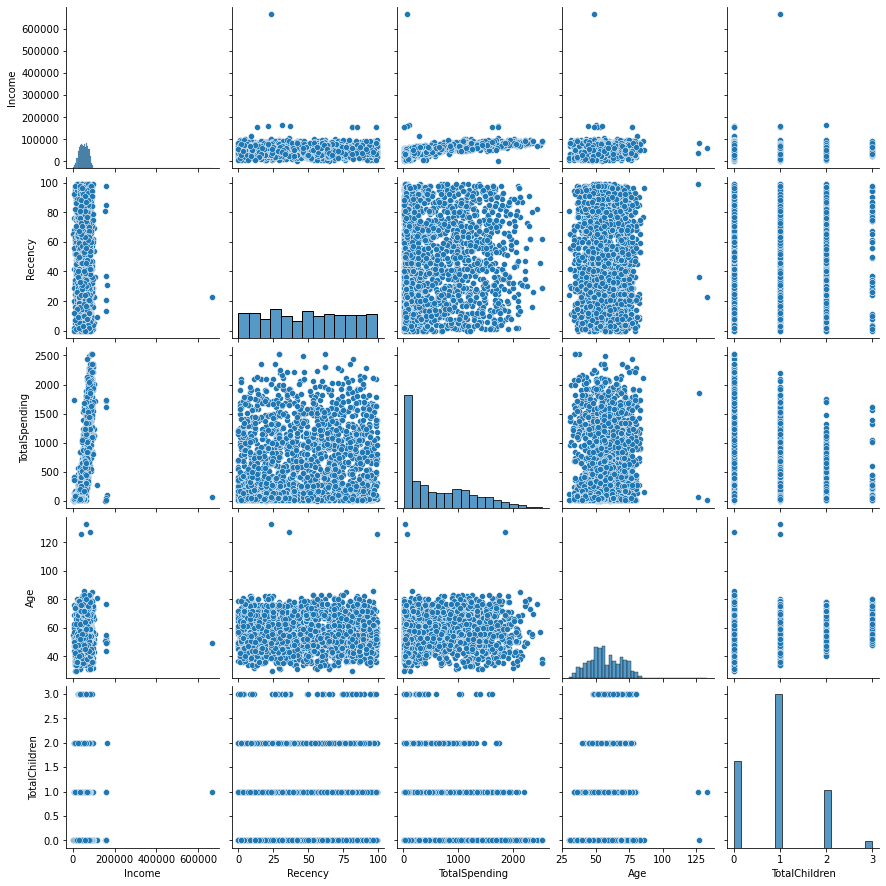

In [21]:
sns.pairplot(df[cols])

In [22]:
#inclome more than 600000 is outlier
cleanDf=cleanDf[(cleanDf["Income"]<600000)]

#Age > 100 are out lier..
cleanDf=cleanDf[(cleanDf["Age"]<100)]

In [23]:
print(df.shape)
print(cleanDf.shape)

(2240, 27)
(2236, 15)


## Correlation Matrics

In [24]:
correlation=cleanDf.corr()

In [25]:
plt.figure(figsize=(7,7))

<Figure size 504x504 with 0 Axes>

<Figure size 504x504 with 0 Axes>

<AxesSubplot:>

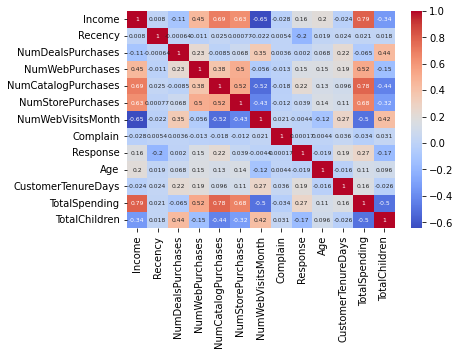

In [26]:
sns.heatmap(
    correlation,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

In [27]:
#   0.79 Income    Total Spending
#   0.69 Income    Catalog Products
#   0.63 Income    Store purchase
# - 0.65 Income    No of web visits
#   0.78 Spending  Catalog Purchases
#   0.68 Spending  Store

# This are some important features

# Encoding

In [28]:
from sklearn.preprocessing import OneHotEncoder

In [29]:
encoder=OneHotEncoder()

encodingColumns=["Education","LivingWith"]

encodedColumns=encoder.fit_transform(cleanDf[encodingColumns])

In [30]:
# one hot encoding doesn't give column's dataframe directly. we have to make dataframes from that columns
# and after converting them to dataframes, we have to add them in original data and remove original not-encoded columns

In [31]:
encodedInDf=pd.DataFrame(
    encodedColumns.toarray(),
    columns=encoder.get_feature_names_out(encodingColumns),
    index=cleanDf.index
)

In [32]:
#drop existing "Education" and "LivingWith" columns from cleanDf and Add new encodedInDf to cleanDf

# dfWithEncoding = encodedDf

encodedDf=pd.concat([cleanDf.drop(columns=encodingColumns),encodedInDf],axis=1)

In [33]:
encodedDf.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,CustomerTenureDays,TotalSpending,TotalChildren,Education_Graduation,Education_Master,Education_Postgraduation,Education_Undergraduation,LivingWith_Alone,LivingWith_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,0.0,1.0,0.0,0.0,1.0


## Scaling

In [34]:
from sklearn.preprocessing import StandardScaler

In [35]:
scaler=StandardScaler()

In [36]:
X=encodedDf

In [37]:
X_scaled=scaler.fit_transform(X)

## PCA -> Dimentionality Reduction

In [38]:
from sklearn.decomposition import PCA

In [47]:
pcaModel=PCA(n_components=3)

In [48]:
X_PCA=pcaModel.fit_transform(X_scaled)

Text(0.5, 0, 'PCA3')

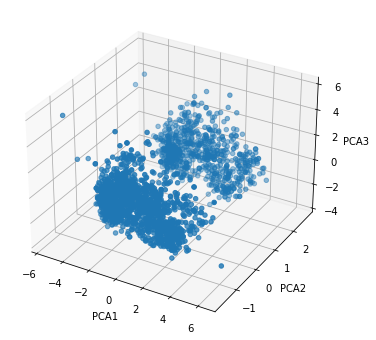

In [57]:
fig=plt.figure(figsize=(8,6))

axis=fig.add_subplot(111,projection="3d")

axis.scatter(X_PCA[:,0],X_PCA[:,1],X_PCA[:,2])

axis.set_xlabel("PCA1")
axis.set_ylabel("PCA2")
axis.set_zlabel("PCA3")

In [56]:
pcaModel.explained_variance_ratio_

array([0.21945824, 0.1078818 , 0.09588633])

## Analys the K value

### Two methods are there, Elbow method and Sihoutte score method

In [58]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

#### Kmean

Text(0, 0.5, 'WCSS')

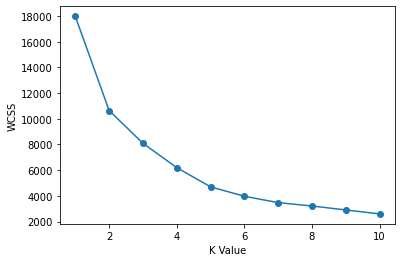

In [71]:
wcss=[]

for i in range(1,11):
    kmean=KMeans(n_clusters=i,random_state=42)
    kmean.fit_transform(X_PCA)
    wcss.append(kmean.inertia_)
    
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel("K Value")
plt.ylabel("WCSS")

In [72]:
K_value=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
print(K_value.elbow)

4


#### Silhoutte Score

In [66]:
from sklearn.metrics import silhouette_score

scores=[]

for i in range (2,11):
    kmean=KMeans(n_clusters=i,random_state=42)
    label=kmean.fit_predict(X_PCA)
    score=silhouette_score(X_PCA,label)
    scores.append(score)

Text(0, 0.5, 'Silhoutte Score')

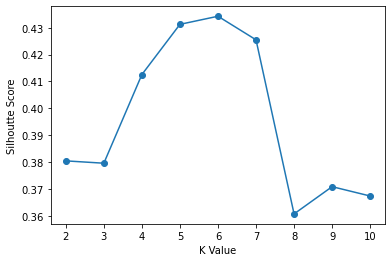

In [69]:
plt.plot(range(2,11),scores,marker='o')
plt.xlabel("K Value")
plt.ylabel("Silhoutte Score")

#### Plotting in same graph

Text(0, 0.5, 'Sihautte Score')

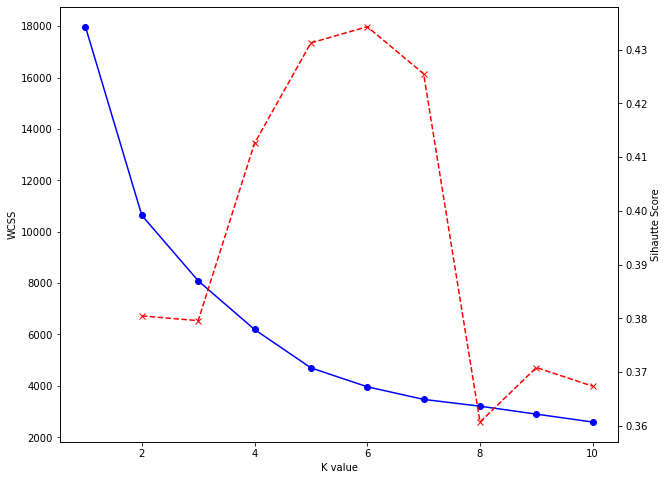

In [96]:
figure,axisPair1=plt.subplots(figsize=(10,8))

axisPair1.plot(range(1,11),wcss,marker='o',color="blue")
axisPair1.set_xlabel("K value")
axisPair1.set_ylabel("WCSS")


axisPair2=axisPair1.twinx()
axisPair2.plot(range(2,11),scores,marker='x',color='Red',linestyle='--')
axisPair2.set_ylabel("Sihautte Score")

## Kmean vs Agglomerative Clustering visulization

In [97]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

In [98]:
kMeanModel=KMeans(n_clusters=4,random_state=42)

labelPredictKMean=kMeanModel.fit_predict(X_scaled)

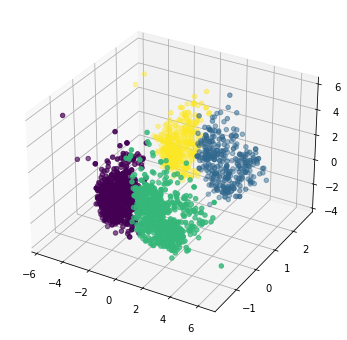

In [100]:
fig=plt.figure(figsize=(8,6))

axis=fig.add_subplot(111,projection="3d")

axis.scatter(X_PCA[:,0],X_PCA[:,1],X_PCA[:,2],c=labelPredictKMean)

In [104]:
agglomerativeModel=AgglomerativeClustering(n_clusters=4)
labelPredictAgglo=agglomerativeModel.fit_predict(X_scaled)

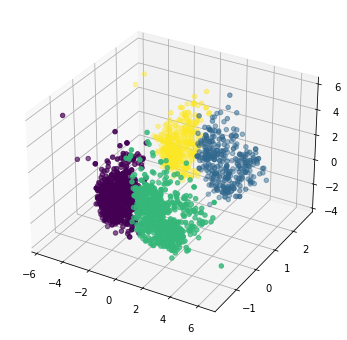

In [105]:
fig=plt.figure(figsize=(8,6))

axis=fig.add_subplot(111,projection="3d")

axis.scatter(X_PCA[:,0],X_PCA[:,1],X_PCA[:,2],c=labelPredictKMean)

## Charecterization of Clusters

In [107]:
#add cluster column to X
X["Cluster"]=labelPredictKMean

<AxesSubplot:xlabel='Cluster', ylabel='count'>

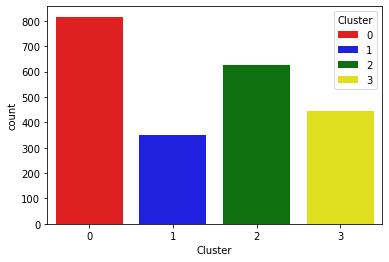

In [110]:
colorPalette=["red","blue","green","yellow"]

sns.countplot(x=X["Cluster"],palette=colorPalette,hue=X["Cluster"])

## Cluster Summery

In [111]:
clusterSummary=X.groupby("Cluster").mean()

In [113]:
print(clusterSummary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
Cluster                                                                
0        37279.957429  49.203431           2.515931         2.846814   
1        70903.761436  50.434286           1.865714         5.802857   
2        70924.626608  48.825879           2.167732         5.701278   
3        37277.578853  48.326577           2.563063         2.740991   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Cluster                                                                        
0                   0.763480           3.727941           6.536765  0.009804   
1                   5.045714           8.451429           3.705714  0.005714   
2                   5.095847           8.519169           3.746006  0.007987   
3                   0.846847           3.662162           6.569820  0.011261   

         Response        Age  CustomerTenureDays  TotalSpending  \
Cluster            